# CSE 242 – Assignment 1, Part 3: PCA (Q2–Q4)

In [56]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Q2 – Correlated Gaussian data

sample covariance:
 [[ 6.79513694 -0.21360246]
 [-0.21360246  1.12691167]]
sample correlation: -0.07719020847275794


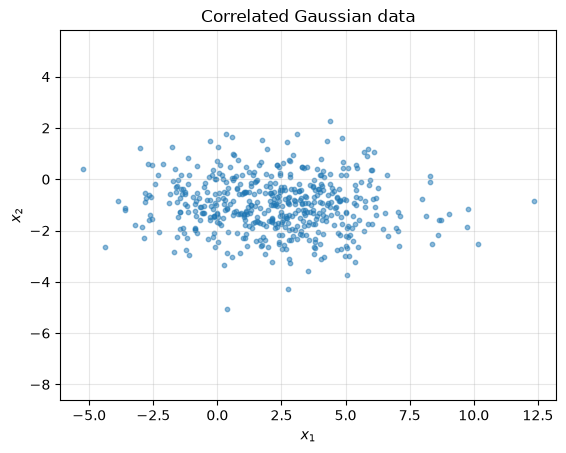

In [84]:
def generate_data(n_samples=500, seed=0, mean=None, covariance=None):
    mean = np.array([2.0, -1.0]) if mean is None else np.array(mean, dtype=float)
    covariance = (np.array([[7.0, -0.2], [-0.2, 1.2]]) if covariance is None
                  else np.array(covariance, dtype=float))
    rng = np.random.default_rng(seed)
    return rng.multivariate_normal(mean, covariance, size=n_samples)


X = generate_data()
print("sample covariance:\n", np.cov(X, rowvar=False))
print("sample correlation:", np.corrcoef(X, rowvar=False)[0, 1])

plt.scatter(X[:, 0], X[:, 1], s=10, alpha=0.5)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Correlated Gaussian data")
plt.axis("equal")
plt.grid(alpha=0.3)
plt.show()

In [86]:
S = np.cov(X, rowvar=False)
rho = np.corrcoef(X, rowvar=False)[0, 1]
direction = "positively" if rho > 0 else "negatively"
strength = "strong" if abs(rho) >= 0.7 else "moderate" if abs(rho) >= 0.3 else "weak"
wider, narrower = ("x1", "x2") if S[0, 0] > S[1, 1] else ("x2", "x1")

print(f"The data are {direction} correlated (rho = {rho:.3f}, a {strength} linear relationship).")
print(f"Var({wider}) = {max(S[0, 0], S[1, 1]):.3f} is larger than Var({narrower}) = {min(S[0, 0], S[1, 1]):.3f}, "
      f"so the cloud is more spread out along {wider}.")

The data are negatively correlated (rho = -0.077, a weak linear relationship).
Var(x1) = 6.795 is larger than Var(x2) = 1.127, so the cloud is more spread out along x1.


## Q3 – PCA

From Q1, $\mathrm{Var}(u^\top X)=u^\top\Sigma u$. Maximizing it subject to $u^\top u=1$ gives $\Sigma u=\lambda u$, with variance $\lambda$ along $u$. So the principal components are the eigenvectors of $\Sigma$, ordered by eigenvalue.

In [87]:
def pca(X):
    X = np.asarray(X, dtype=float)
    n = X.shape[0]

    # 1. center: subtract the mean (the derivation uses X - mu)
    mean = X.mean(axis=0)
    centered = X - mean

    # 2. covariance: S = Xc^T Xc / (n-1), the estimate of Sigma
    covariance = centered.T @ centered / (n - 1)

    # 3. eigendecomposition: S u = lambda u
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)

    # 4. select components: sort by descending eigenvalue (= variance along u)
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = np.clip(eigenvalues[order], 0.0, None)
    components = eigenvectors[:, order]

    scores = centered @ components
    return {"mean": mean, "centered": centered, "covariance": covariance,
            "eigenvalues": eigenvalues, "components": components, "scores": scores}


result = pca(X)
print("eigenvalues:", result["eigenvalues"])
print("components (columns):\n", result["components"])

eigenvalues: [6.80317498 1.11887363]
components (columns):
 [[-0.99929271 -0.03760421]
 [ 0.03760421 -0.99929271]]


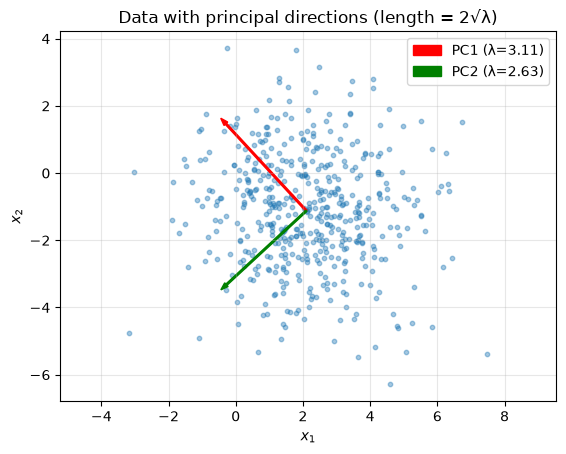

In [78]:
m, W, lam = result["mean"], result["components"], result["eigenvalues"]
plt.scatter(X[:, 0], X[:, 1], s=10, alpha=0.4)
for k, c in enumerate(["red", "green"]):
    v = 2 * np.sqrt(lam[k]) * W[:, k]
    plt.arrow(*m, *v, color=c, width=0.05, label=f"PC{k+1} (λ={lam[k]:.2f})")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Data with principal directions (length = 2√λ)")
plt.axis("equal")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Q4 – Explained variance

$\text{EVR}_k = \lambda_k / \sum_j \lambda_j$

In [79]:
def explained_variance(eigenvalues):
    eigenvalues = np.asarray(eigenvalues, dtype=float)
    return eigenvalues / eigenvalues.sum()


evr = explained_variance(lam)
for k, f in enumerate(evr, 1):
    print(f"PC{k}: {100*f:.2f}%")

PC1: 54.21%
PC2: 45.79%


In [80]:
print(f"PC1 keeps {100 * evr[0]:.1f}% of the variance, so reducing 2-D to 1-D loses {100 * evr[1]:.1f}%.")
print("Trade-off: fewer dimensions are cheaper and less redundant, but every dropped component loses its share of the variance.")

PC1 keeps 54.2% of the variance, so reducing 2-D to 1-D loses 45.8%.
Trade-off: fewer dimensions are cheaper and less redundant, but every dropped component loses its share of the variance.
